[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/7_eigenvectors_of_G_per_scale.ipynb)

# Leading eigenvectors of G(x) at each noise level

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Split G(x) into its contributions from each noise level, $M_t(x)$, and plot the leading eigenvectors of $M_t(x)$ against the noise level, for the Inception models of V1 and V4 and the example images of the landing page (task 1 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_g_per_scale` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 6 min on a GPU.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 3 μs, sys: 1e+03 ns, total: 4 μs
Wall time: 5.01 μs


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of this notebook (`figures/per_scale.py`, shared with notebook 8), and set the parameters: the encoder, the example images, the number of samples per noise level, and where the figures go.

<details><summary>Details</summary>

* `load_examples` loads the example images, `compute_per_scale` computes $M_t(x)$ at each noise level for each of them, `plot_per_scale` draws the figure of one image (the sign of each eigenvector chosen by `align_signs`) and returns the data it shows, and `compute_summary` and `plot_summary` summarise the results across the images.

</details>

time: 1 sec

In [2]:
%%time

import copy
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

# the figures/ folder of this repository (its plot helpers)
sys.path.insert(0, str(root))
print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.diffusion.model import build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.utils import get_device
from figures.per_scale import (
    compute_per_scale,
    compute_summary,
    load_examples,
    plot_per_scale,
    plot_summary,
)

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the example images of the landing page (https://multigeom.github.io): the frog of
    # paper Fig. 3D (the first TinyImageNet training image of the class n01644900),
    # then test images, by their index among the TinyImageNet validation images in
    # sorted file order (the test images of notebook 4)
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187],
    # Monte-Carlo samples per noise level (the paper uses 200 for G(x))
    "n_samples": 200,
    # leading eigenvectors kept and drawn at each noise level
    "n_eigvecs": 4,
    # where the figures are saved (one per image), their resolution in the file and
    # on screen, and the images whose figures stay in the notebook (each is about 1 MB)
    "figure_dir": "assets/figures/task1",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["frog"],
}

# the diffusion and estimator configs (packaged with multigeom)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 3.89 s, sys: 227 ms, total: 4.12 s
Wall time: 1.69 s


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints is skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", ignore_patterns="archive/*"
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 87.3 ms, sys: 19.9 ms, total: 107 ms
Wall time: 203 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the example images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet: the frog and the test images (nothing if already there)
download_tinyimagenet()

CPU times: user 353 μs, sys: 24 μs, total: 377 μs
Wall time: 306 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute $M_t(x)$ at each noise level

G(x) adds up, over the noise levels t, the information that the responses carry about the image: $G(x) = \int M_t(x)\, d\log t$. We estimate the integrand $M_t(x)$ at each of the 24 noise levels of the paper's grid, for each example image and for the models of V1 and V4, and keep its leading 4 eigenvectors and eigenvalues.

<details><summary>Details</summary>

* **Definition.** With $x_t = x + \sqrt{t}\,\epsilon$ the image plus Gaussian noise of variance $t$, and $r, r'$ two responses drawn independently given $x_t$,
  $$M_t(x) = \tfrac12\, \mathbb{E}\left[\tfrac1t \left(\hat x(x_t, r) - \hat x(x_t, r')\right)\left(\hat x(x_t, r) - \hat x(x_t, r')\right)^\top\right],$$
  where $\hat x(x_t, r) = \mathbb{E}[x \mid x_t, r]$ is the denoiser of the conditional diffusion model. It is the integrand of G(x), without the integral over $t$.
* **Noise levels.** Those of the paper's G(x): the DDPM steps 40, 80, ..., 960, that is $\tau = \log t$ from −3.9 to 9.3 (natural log, $t$ in the units of the image, whose pixels are in [−1, 1]). The package calls the noise variance τ, so the `log_tau` that `compute_g_per_scale` returns is $\tau = \log t$ here.
* **Algorithm.** Algorithm 1 of the paper, one noise level at a time: the 200 rows of D drawn at that level, without the trapezoid weight, then one SVD per level. As for G(x), the responses are drawn given the denoised image, $r \sim p(r \mid \hat x(x_t))$.
* **The same samples as G(x).** With the same seed, `compute_g_per_scale` draws the samples of `compute_g`, so the $M_t(x)$ weighted by the trapezoid rule add up to G(x) (checked by the tests of the package). The test images have the seeds of the pipeline (notebook 4), the frog that of notebook 3.
* **Noise of the estimate.** Each $M_t(x)$ rests on 200 samples, 24 times fewer than G(x). At fine noise levels ($\tau < 2$) its leading eigenvalues are nearly equal, and its leading eigenvectors change with the seed: for test image 0, two seeds agree with $|\cos|$ between 0.11 and 0.97 on the leading eigenvector, against at least 0.94 at $\tau > 2$. With 2,000 samples per level (`"n_samples": 2000`, about 10 times longer), they agreed with $|\cos| \ge 0.93$ at the fine levels we tested.

</details>

time: 5 min

In [5]:
%%time

# 1. estimator settings: those of the paper, with n_samples Monte-Carlo samples per
# noise level, and the n_eigvecs leading eigenpairs kept at each level
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]

# 2. the example images, with their seeds
examples = load_examples(PARAMS, int(cfg.seed))

# 3. the noise schedule of the diffusion models (the ᾱ of each DDPM step)
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 4. for each area: load its encoder and diffusion model, then compute M_t(x) of every
# image; results[area][name] holds tau = log t, the eigenvalues and the eigenvectors
results = {}
for area in PARAMS["areas"]:
    encoder, unet, _ = load_models(
        PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
    )
    results[area] = compute_per_scale(
        examples, encoder, unet, alphas_cumprod, cfg, device
    )
    print(area, "done:", len(results[area]), "images")

V1 done: 13 images


V4 done: 13 images
CPU times: user 3min 55s, sys: 1min 5s, total: 5min
Wall time: 5min


## 5. Plot the leading eigenvectors at each noise level

One figure per image, saved to `assets/figures/task1/eigenvectors_per_scale_<image>.png`; to keep the notebook small, it shows only those of the images in `PARAMS["show"]` (the frog). Each figure has the image (A), the leading 4 eigenvectors of $M_t(x)$ at each noise level for V1 (B) and V4 (C), from the finest noise level (left) to the coarsest (right), and their eigenvalues (D).

<details><summary>Details</summary>

* Each eigenvector is drawn like those of Fig. 3E: red positive, blue negative, scaled to its own 99th percentile of |v|.
* The sign of an eigenvector is arbitrary. For display, each takes the sign that agrees with the same eigenvector at the next coarser level, and those of the coarsest level have a positive sum.
* In D, the leading eigenvalue of each area is thick and the next three are thin; the columns are those of B and C.

</details>

time: 16 secs

13 figures saved in assets/figures/task1
CPU times: user 17.8 s, sys: 305 ms, total: 18.1 s
Wall time: 16.1 s


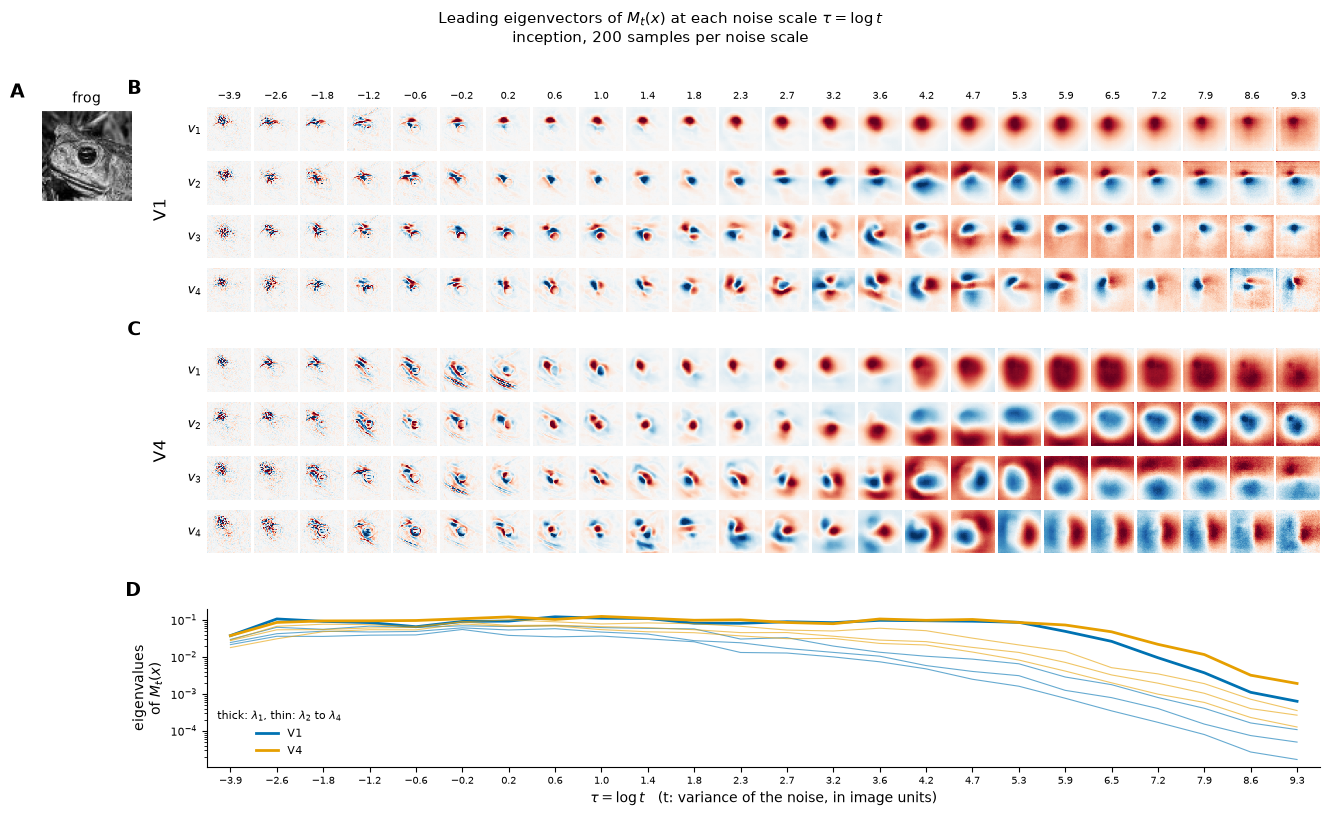

In [6]:
%%time

# 1. the folder of the figures, and the title of every figure
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
suptitle = (
    r"Leading eigenvectors of $M_t(x)$ at each noise scale $\tau = \log t$"
    f"\n{PARAMS['encoder']}, {PARAMS['n_samples']} samples per noise scale"
)

# 2. one figure per image: draw it, keep the data it shows, and save it; only the
# figures of the images in PARAMS["show"] stay in the notebook
plotted = {}
for name, (image, _) in examples.items():
    records = {area: results[area][name] for area in PARAMS["areas"]}
    fig, plotted[name] = plot_per_scale(image, records, PARAMS, name, suptitle)
    fig.savefig(
        figure_dir / f"eigenvectors_per_scale_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)

# 3. where the figures are
print(len(plotted), "figures saved in", figure_dir)

## 6. Summary across the images

How much the leading eigenvector of $M_t(x)$ depends on the image at each noise level, and how large its eigenvalue is, over the example images. The figure is also saved to `assets/figures/task1/eigenvectors_per_scale_summary.png`.

<details><summary>Details</summary>

* **A**: for each noise level, the |cos| between the leading eigenvectors of two different images, averaged over all the pairs of images. 1 means that the leading eigenvector is the same for every image; at the finest levels, part of the difference is the Monte-Carlo noise of the estimate (see the details of section 4).
* **B**: the leading eigenvalue of each image, median over the images.
* The printed noise levels are those where the leading eigenvalue of V4 is larger than that of V1 for every image.

</details>

time: <1 sec

V4 > V1 in every image at tau = [-1.2 -0.6  0.2  5.9  6.5  7.2  7.9  8.6  9.3]
CPU times: user 292 ms, sys: 1.88 ms, total: 294 ms
Wall time: 107 ms


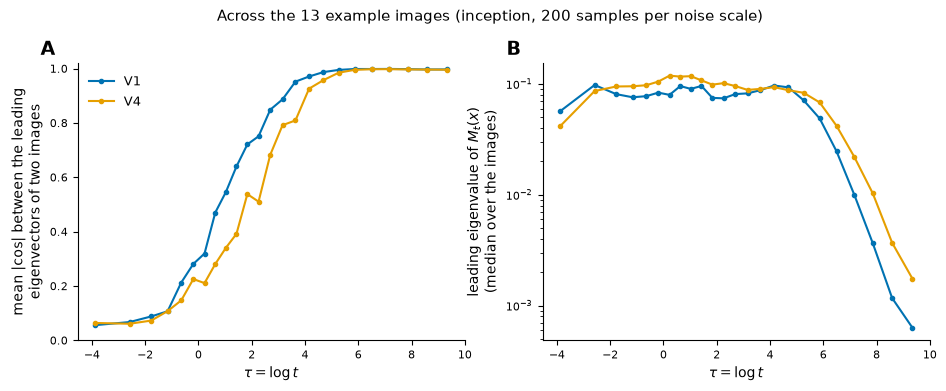

In [7]:
%%time

# 1. per noise level, across the example images: how similar their leading
# eigenvectors are, and their leading eigenvalues
summary = compute_summary(results, PARAMS["areas"])

# 2. the summary figure, also saved
fig, summary_plotted = plot_summary(summary, PARAMS)
fig.savefig(
    figure_dir / "eigenvectors_per_scale_summary.png",
    dpi=PARAMS["file_dpi"],
    bbox_inches="tight",
)

# 3. the noise levels where the leading eigenvalue of V4 is the larger one, in every
# image
every_image = summary["second_larger"] == 1
print("V4 > V1 in every image at tau =", summary["log_t"][every_image].numpy().round(1))

## 7. Conclusion

* **What we computed.** $M_t(x)$, the integrand of G(x), at the 24 noise levels of the paper's grid ($\tau = \log t$ from −3.9 to 9.3), for the 13 example images of the landing page and the Inception models of V1 and V4, with 200 samples per level: about 5 min on one GPU. The figures are in `assets/figures/task1/`.
* **From the model to the image.** At coarse noise levels ($\tau \ge 5.9$) the leading eigenvectors are smooth patterns over the receptive fields, the same for every image (mean |cos| between two images: 1.00 in both areas): the noise hides the image, and what is left is the structure of the model. As the noise decreases, they shrink and follow the image (the eye of the frog): the mean |cos| between two images falls to 0.55 (V1) and 0.34 (V4) at $\tau = 1.0$, and to 0.06 at the finest level, where part of the difference is Monte-Carlo noise.
* **Where the information lies.** The leading eigenvalue (median over the images) stays between 0.07 and 0.12 from $\tau = -2.6$ to 5.3, then falls by a factor of about 150 (V1) and 50 (V4) up to the coarsest level. At coarse levels ($\tau \ge 5.9$) it is larger for V4 than for V1 in every image, about 2 to 3 times (medians at $\tau \ge 7.2$), consistent with the larger receptive fields of V4. Between $\tau = -1.8$ and 2.7 it is also larger for V4 in most images, around $\tau = 3$ to 5 in about half of them, and at the two finest levels it is larger for V1 in most images.
* **Caveat.** With 200 samples per noise level, the leading eigenvectors at fine levels ($\tau < 2$) change from one seed to the next (details of section 4); those at coarse levels do not. Raise `"n_samples"` before reading the fine levels in detail.
* **Next steps.** Task 2 of the note, the same decomposition for the stimulus statistics alone, $M^{\rm env}_t(x)$, drawn next to these figures, is notebook 8; then the spectra $\rho^{\rm env}(\tau)$ and $\rho(\tau)$ (tasks 3 and 4).